In [1]:
import gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from collections import deque
import random
import matplotlib.pyplot as plt
import torch.nn.functional as F
from torch.distributions import Categorical


In [2]:
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)



In [3]:
class ActorCritic(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super().__init__()
        self.fc1 = nn.Linear(state_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.policy_head = nn.Linear(hidden_dim, action_dim)  # Actor
        self.value_head = nn.Linear(hidden_dim, 1)             # Critic

    def forward(self, state):
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        policy = F.softmax(self.policy_head(x), dim=-1)
        value = self.value_head(x)
        return policy, value


In [4]:
def train_actor_critic(config, seed=0):
    set_seed(seed)
    env = gym.make("CartPole-v1")
    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n

    model = ActorCritic(state_dim, action_dim, hidden_dim=config["hidden_dim"])
    optimizer = optim.Adam(model.parameters(), lr=config["lr"])
    
    episode_rewards, env_steps = [], []
    total_steps = 0

    while total_steps < config["max_env_steps"]:
        state, _ = env.reset()
        done = False
        total_reward = 0

        while not done:
            state_tensor = torch.tensor(state, dtype=torch.float32)
            action_probs, state_value = model(state_tensor)
            dist = torch.distributions.Categorical(action_probs)
            action = dist.sample()

            next_state, reward, terminated, truncated, _ = env.step(action.item())
            done = terminated or truncated

            next_state_tensor = torch.tensor(next_state, dtype=torch.float32)
            _, next_state_value = model(next_state_tensor)

            target_value = reward + (0 if done else config["gamma"] * next_state_value.item())
            advantage = target_value - state_value.item()

            actor_loss = -dist.log_prob(action) * advantage
            critic_loss = F.mse_loss(state_value.squeeze(), torch.tensor(target_value))
            loss = actor_loss + critic_loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            state = next_state
            total_reward += reward
            total_steps +=1

        episode_rewards.append(total_reward)
        env_steps.append(total_steps)
        print(f"[AC] Step {total_steps}/{config['max_env_steps']} | Reward: {total_reward:.2f}")

    env.close()
    return episode_rewards, env_steps


In [5]:
def train_A2C(config, seed=0):
    set_seed(seed)
    env = gym.make("CartPole-v1")
    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n
    model = ActorCritic(state_dim, action_dim, hidden_dim=config["hidden_dim"])
    optimizer = optim.Adam(model.parameters(), lr=config["lr"])

    episode_rewards, env_steps = [], []
    total_steps = 0

    while total_steps < config["max_env_steps"]:
        state, _ = env.reset()
        done=False
        total_reward = 0
        log_probs, values, rewards,entropies = [], [], [], []

        while not done:
            state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
            action_probs, state_value = model(state_tensor)
            dist = Categorical(action_probs)
            action = dist.sample()

            log_prob = dist.log_prob(action)
            entropy = dist.entropy()

            next_state, reward, terminated, truncated, _ = env.step(action.item())
            done = terminated or truncated

            log_probs.append(log_prob)
            values.append(state_value)
            rewards.append(reward)
            entropies.append(entropy)

            state = next_state
            total_reward += reward
            total_steps += 1

        returns = []
        G = 0
        for r in reversed(rewards):
            G = r + config["gamma"] * G
            returns.insert(0, G)
        returns = torch.tensor(returns, dtype=torch.float32)
        values = torch.cat(values).squeeze()
        advantages = returns - values.detach()

        log_probs = torch.stack(log_probs)
        entropies = torch.stack(entropies)

        actor_loss = - (log_probs * advantages).sum()
        critic_loss = F.mse_loss(values, returns)
        entropy_bonus = entropies.sum()

        loss = actor_loss + critic_loss - 0.01*entropy_bonus

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        episode_rewards.append(total_reward)
        env_steps.append(total_steps)
        print(f"[A2C] Step {total_steps}/{config['max_env_steps']} | Reward: {total_reward:.2f}")

    env.close()
    return episode_rewards, env_steps

In [7]:
config = {
    "lr": 5e-4,
    "gamma": 0.99,
    "hidden_dim": 128,
    "max_env_steps": 1e6
}

ac_results = []

for i in range(5):
    print(f"\n=== AC Run {i+1} ===")
    ac_rewards, ac_steps = train_actor_critic(config, seed=42 + i)
    ac_results.append((ac_rewards, ac_steps))



=== AC Run 1 ===
[AC] Step 17/1000000.0 | Reward: 17.00
[AC] Step 27/1000000.0 | Reward: 10.00
[AC] Step 59/1000000.0 | Reward: 32.00
[AC] Step 75/1000000.0 | Reward: 16.00
[AC] Step 128/1000000.0 | Reward: 53.00
[AC] Step 137/1000000.0 | Reward: 9.00
[AC] Step 147/1000000.0 | Reward: 10.00
[AC] Step 159/1000000.0 | Reward: 12.00
[AC] Step 171/1000000.0 | Reward: 12.00
[AC] Step 186/1000000.0 | Reward: 15.00
[AC] Step 196/1000000.0 | Reward: 10.00
[AC] Step 204/1000000.0 | Reward: 8.00
[AC] Step 212/1000000.0 | Reward: 8.00
[AC] Step 223/1000000.0 | Reward: 11.00
[AC] Step 232/1000000.0 | Reward: 9.00
[AC] Step 242/1000000.0 | Reward: 10.00
[AC] Step 252/1000000.0 | Reward: 10.00
[AC] Step 266/1000000.0 | Reward: 14.00
[AC] Step 282/1000000.0 | Reward: 16.00
[AC] Step 292/1000000.0 | Reward: 10.00
[AC] Step 300/1000000.0 | Reward: 8.00
[AC] Step 308/1000000.0 | Reward: 8.00
[AC] Step 318/1000000.0 | Reward: 10.00
[AC] Step 329/1000000.0 | Reward: 11.00
[AC] Step 339/1000000.0 | Reward

In [8]:
a2c_results = []
for i in range(5):

    print(f"\n=== A2C Run {i+1} ===")
    a2c_rewards, a2c_steps = train_A2C(config, seed=42 + i)
    a2c_results.append((a2c_rewards, a2c_steps))


=== A2C Run 1 ===
[A2C] Step 44/1000000.0 | Reward: 44.00
[A2C] Step 59/1000000.0 | Reward: 15.00
[A2C] Step 77/1000000.0 | Reward: 18.00
[A2C] Step 121/1000000.0 | Reward: 44.00
[A2C] Step 133/1000000.0 | Reward: 12.00
[A2C] Step 156/1000000.0 | Reward: 23.00
[A2C] Step 191/1000000.0 | Reward: 35.00
[A2C] Step 213/1000000.0 | Reward: 22.00
[A2C] Step 256/1000000.0 | Reward: 43.00
[A2C] Step 315/1000000.0 | Reward: 59.00
[A2C] Step 327/1000000.0 | Reward: 12.00
[A2C] Step 348/1000000.0 | Reward: 21.00
[A2C] Step 359/1000000.0 | Reward: 11.00
[A2C] Step 396/1000000.0 | Reward: 37.00
[A2C] Step 419/1000000.0 | Reward: 23.00
[A2C] Step 440/1000000.0 | Reward: 21.00
[A2C] Step 455/1000000.0 | Reward: 15.00
[A2C] Step 485/1000000.0 | Reward: 30.00
[A2C] Step 518/1000000.0 | Reward: 33.00
[A2C] Step 559/1000000.0 | Reward: 41.00
[A2C] Step 576/1000000.0 | Reward: 17.00
[A2C] Step 603/1000000.0 | Reward: 27.00
[A2C] Step 622/1000000.0 | Reward: 19.00
[A2C] Step 643/1000000.0 | Reward: 21.00


In [9]:
import csv
import os
import pandas as pd

def save_ac_a2c_to_csv(results, method_label, filename="ac_a2c_results.csv"):
    file_exists = os.path.exists(filename)
    with open(filename, mode='a', newline='') as file:
        writer = csv.writer(file)
        if not file_exists:
            writer.writerow(["Method", "Run", "EnvStep", "EpisodeReturn"])
        for run_id, (rewards, steps) in enumerate(results, 1):
            for step, reward in zip(steps, rewards):
                writer.writerow([method_label, run_id, step, reward])

def plot_ac_a2c_from_csv(filename="ac_a2c_results.csv", method_label="AC", window_size=50):
    df = pd.read_csv(filename)
    plt.figure(figsize=(12, 6))
    for run_id in sorted(df[df['Method'] == method_label]['Run'].unique()):
        run_df = df[(df['Method'] == method_label) & (df['Run'] == run_id)].sort_values(by='EnvStep')
        rewards = run_df['EpisodeReturn'].values
        steps = run_df['EnvStep'].values

        if len(rewards) >= window_size:
            smoothed_rewards = np.convolve(rewards, np.ones(window_size) / window_size, mode='valid')
            aligned_steps = steps[window_size - 1:]
        else:
            smoothed_rewards = rewards
            aligned_steps = steps

        plt.plot(aligned_steps, smoothed_rewards, label=f"{method_label} Run {run_id}", linewidth=1)

    plt.xlabel("Environment Steps")
    plt.ylabel(f"Smoothed Episode Reward ({window_size})")
    plt.title(f"{method_label} Performance over Multiple Runs")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

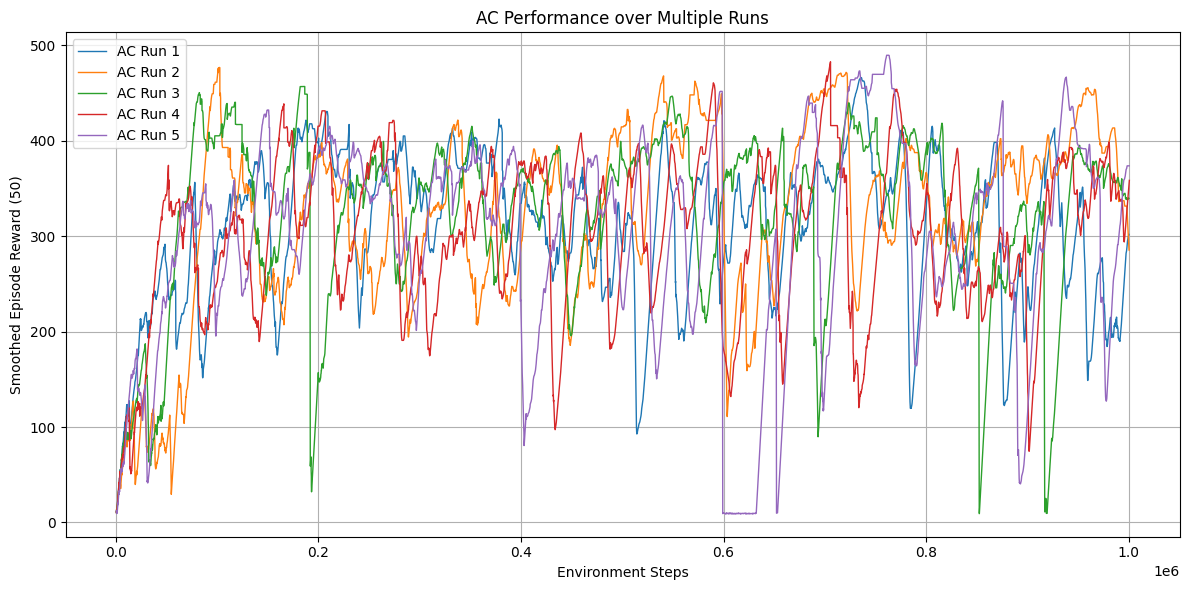

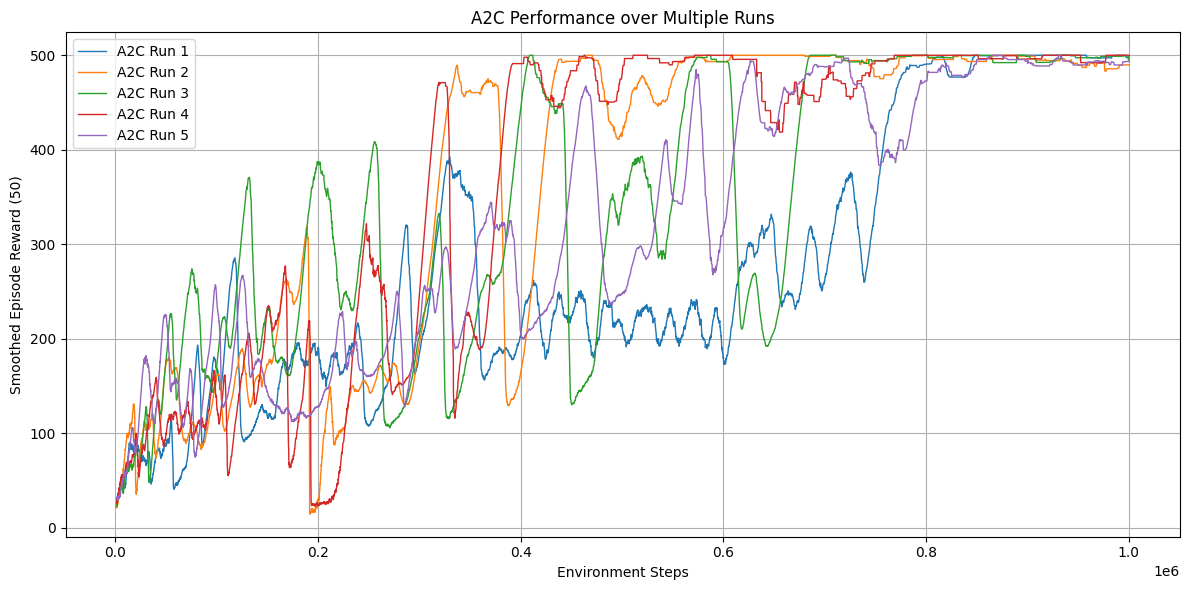

In [10]:
save_ac_a2c_to_csv(ac_results, "AC")
save_ac_a2c_to_csv(a2c_results, "A2C")

plot_ac_a2c_from_csv(method_label="AC")
plot_ac_a2c_from_csv(method_label="A2C")